In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import torch


device = "cuda"

# Utils

In [2]:
def visualize_events(events, width, height, t_end, t_start):
    # 1. Extract and Move to CPU
    x = events['x'].detach().cpu().numpy().astype(int)
    y = events['y'].detach().cpu().numpy().astype(int)
    t = events['t'].detach().cpu().numpy()
    p = events['p'].detach().cpu().numpy() # Assuming p is 0 (OFF) and 1 (ON) or -1/1

    # Filter by time (optional: usually you want the last N milliseconds of the batch)
    mask = np.logical_and(t_start <= t, t <= t_end)
    x, y, p = x[mask], y[mask], p[mask]

    # 2. Create Blank Canvas (White background often looks cleaner for papers)
    # Using White Background:
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # 3. Define Colors (BGR for OpenCV, RGB for Matplotlib)
    # Standard Convention: Red = ON (+), Blue = OFF (-)
    color_on = np.array([0, 0, 255])   # Red in BGR (if using cv2) / Blue in RGB
    color_off = np.array([255, 0, 0])  # Blue in BGR / Red in RGB

    # Note: Check your polarity encoding.
    # ESIM often uses 1 for ON, 0 or -1 for OFF.
    mask_pos = (p == 1)
    mask_neg = (p == 0) | (p == -1)

    # 4. Draw Events
    # We simply set the pixel color.
    # For a 'heatmap' style where density matters, you would need accumulation,
    # but for crisp feature visualization, direct setting is usually clearer.

    if len(x) > 0:
        # Set OFF events (Blue)
        img[y[mask_neg], x[mask_neg]] = color_off

        # Set ON events (Red) - drawn second to overlay if they overlap
        img[y[mask_pos], x[mask_pos]] = color_on

    return img

# load the video

In [3]:
FPS = 90
dt = 1 / FPS

In [4]:
video_input = "high_speed_output.mp4"
cap = cv2.VideoCapture(video_input)

frames = []
frame_idx = 0

if not cap.isOpened():
    print("Couldn't open the file !")

else:
    while True:

        ret, frame = cap.read()

        if not ret:
            break

        frames.append(np.mean(frame, axis=-1))
        frame_idx += 1


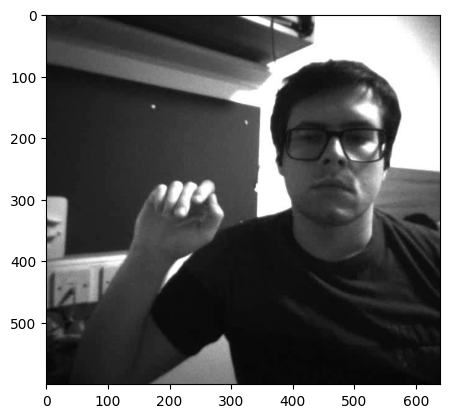

In [5]:
plt.imshow(frames[0], cmap='gray')

# save the individual frames

In [6]:
root_save = os.path.join(".", "raw_frames")

os.makedirs(root_save, exist_ok=True)

for i, frame in enumerate(frames):
    filepath = os.path.join(root_save, f"{i}.png")
    cv2.imwrite(filepath, frame)

# Simulate with the DVS

In [7]:
import esim_torch

contrast_thresholds_neg = 0.2
contrast_thresholds_pos = 0.2

# create and reset simulator
event_simulator = esim_torch.ESIM(
            contrast_threshold_neg=contrast_thresholds_neg,
            contrast_threshold_pos=contrast_thresholds_pos,
            refractory_period_ns=0,
        )
event_simulator.reset()

In [8]:
# prepare the input
input_frames_dvs = np.array(frames.copy())
input_images = np.log(input_frames_dvs / 255.0 + 1e-4).astype(np.float32)
timestamps_ns = (np.arange(0, len(input_images)) * dt)

input_images = torch.from_numpy(input_images).to(device, non_blocking=True)
timestamps_ns = (1e9 * timestamps_ns).astype(np.int64)
timestamps_ns_t = torch.from_numpy(timestamps_ns).to(device, non_blocking=True)

In [9]:

# reset + simulate events
events = event_simulator.forward(input_images, timestamps_ns_t)
x, y, t, p = events["x"], events["y"], events["t"], events["p"]  # GPU tensors


915


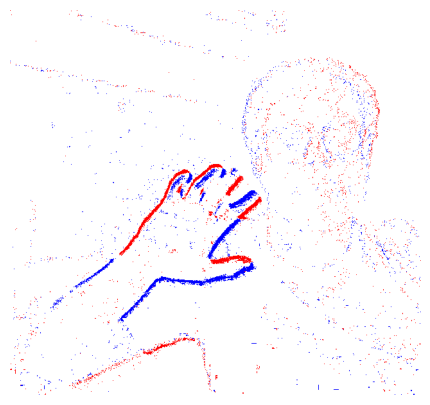

In [10]:
H, W = input_frames_dvs.shape[1], input_frames_dvs.shape[2]
print(len(input_images))

start_frame = 900
end_frame = 902
ms_period = round((end_frame - start_frame) / FPS * 1e3, 1)

# Generate the image
event_viz = visualize_events(events, width=W, height=H, t_start = int(start_frame / FPS * 1e9), t_end= int(end_frame / FPS * 1e9) ) # 30ms window

# Display
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB)) # Convert BGR to RGB for matplotlib00000
#plt.title(f"DVS Events (Accumulated {ms_period} ms), starting_at {round(start_frame / FPS *1e3, 1)}, ending_at {round(end_frame / FPS *1e3, 1)}")
plt.savefig("events_visualized.jpg")
plt.axis('off')
plt.show()

In [11]:
cv2.imwrite("events_visualized.jpg", cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB))

True

In [19]:
import os
from tqdm import tqdm

delta_t = 2
ms_period = round((delta_t+1) / FPS * 1e3, 1)
folder = f"dvs+bins={ms_period}ms"

os.makedirs(folder, exist_ok=True)
H, W = input_frames_dvs.shape[1], input_frames_dvs.shape[2]
print(len(input_images))


for i in tqdm(range(0, len(input_images) - delta_t)):
    start_frame = i
    end_frame = i + delta_t

    # Generate the image
    event_viz = visualize_events(events, width=W, height=H, t_start = int(start_frame / FPS * 1e9), t_end= int(end_frame / FPS * 1e9) ) # 30ms window
    cv2.imwrite(os.path.join(folder, f"{i}_to_{i+delta_t}.png"), cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB))

915


100%|██████████| 913/913 [04:24<00:00,  3.45it/s]


# Simulate the Retina

In [6]:
def visualize_retina_frames(pos_tensor, neg_tensor, start_idx, end_idx, height, width):
    """
    Visualizes dense retina event frames (T, H, W) as a single Red/Blue image.
    Matches the style of the DVS visualization.
    """
    # 1. Create Blank White Canvas
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # 2. Extract window and collapse time
    # We take the logical OR across the time dimension to see if an event happened
    # in this window. (Summing is also an option if you want density).

    # Slice the tensor [Time, Height, Width]
    # Ensure we are on CPU and numpy
    p_chunk = pos_tensor[start_idx:end_idx].cpu().numpy()
    n_chunk = neg_tensor[start_idx:end_idx].cpu().numpy()

    # Collapse: if ANY frame in the window has a spike, mark it.
    pos_mask = np.any(p_chunk > 0, axis=0) # Shape: (H, W)
    neg_mask = np.any(n_chunk > 0, axis=0)

    # 3. Define Colors (BGR for OpenCV consistency with your previous code)
    color_on = np.array([0, 0, 255])   # Red
    color_off = np.array([255, 0, 0])  # Blue

    # 4. Draw
    # Draw Negative (Blue) first
    img[neg_mask] = color_off
    # Draw Positive (Red) on top
    img[pos_mask] = color_on

    return img

def visualize_heatmap(tensor_data, frame_idx, cmap_name='seismic', normalize_sym=True):
    """
    Visualizes an analog intermediate state (OPL, Voltage) as a heatmap.
    """
    # Extract specific frame
    data = tensor_data[frame_idx].cpu().numpy()

    # Normalize
    if normalize_sym:
        # For OPL (Difference of Gaussians), 0 should be gray.
        # We find the max absolute value to center the colormap at 0.
        max_val = np.max(np.abs(data)) + 1e-5
        norm_data = data / max_val # Now between -1 and 1
        # Shift to 0-1 for matplotlib colormap
        norm_data = (norm_data + 1) / 2.0
    else:
        # For Gain/Voltage (0 to Max)
        min_val = np.min(data)
        max_val = np.max(data) + 1e-5
        norm_data = (data - min_val) / (max_val - min_val)

    # Apply Colormap
    cmap = plt.get_cmap(cmap_name)
    colored_img = cmap(norm_data) # Returns RGBA float 0-1

    # Convert to RGB uint8 0-255
    img_uint8 = (colored_img[:, :, :3] * 255).astype(np.uint8)
    return img_uint8

In [7]:
H, W = frames[0].shape
T = len(frames)

In [14]:
from esim_torch import SiliconRetinaVerboseFloatCUDA, SiliconRetinaFloatCUDAOnline, SiliconRetinaConfig
from esim_torch.silicon_retina_cuda import BLUR_MODE, HPF_MODE, KERNEL_TYPE, Q_FEEDBACK_MODE

cfg = SiliconRetinaConfig(H = H,
                          W = W,
                          alpha1=0.5,
                          alpha2=0.5,
                          V_BIP_LPF_alpha=0.5,
                          lambda_OPL=3.0,
                          G_A_zero = 0.5,
                          lambda_A = 0.5,
                          p1 = 0.25,
                          I_bias_on = 0.01,
                          I_bias_off = 0.01,
                          p2= 1.0,
                          p3 = 0.2,

                          # LIF parameters
                          U_rest_on = -0.05,
                          U_rest_off = -0.05,
                          U_th_on = 0.02,
                          U_th_off = 0.02,
                          U_reset_on = 0.04,
                          U_reset_off = 0.04,

                          # High-pass filter modes
                          HPF1_mode = 0,  # silicon_retina_cuda.HPF_MODE.SUB
                          HPF1_param = 0.5,
                          HPF2_mode = 0,  # silicon_retina_cuda.HPF_MODE.SUB
                          HPF2_param = 0.5,

                          # Blur modes
                          blur1_mode = 0,  # silicon_retina_cuda.BLUR_MODE.BLUR_AVG
                          blur2_mode = 0,  # silicon_retina_cuda.BLUR_MODE.BLUR_AVG

                          # NEW: Kernel configuration
                          kernel1_type = 0,  # silicon_retina_cuda.KERNEL_TYPE.BOX
                          kernel2_type = 0,  # silicon_retina_cuda.KERNEL_TYPE.BOX
                          kernel1_size = 3,
                          kernel2_size = 3,
                          kernel1_sigma = 1.0,
                          kernel2_sigma = 1.0)

model = SiliconRetinaFloatCUDAOnline(silicon_retina_config=cfg)

positive, negative = [], []
opl_storage = []
bip_storage = []
V_LIF_on = []
V_LIF_off = []

folder = os.path.join(".", "retina_visualization")
os.makedirs(folder, exist_ok=True)

model.reset()
for t in tqdm(range(1, T+1, 1)):

    input = (frames[t-1][None] / 255.).astype(np.float32)
    input = torch.Tensor(input).to(device)
    p, n = model(input, t)
    positive.append((p.clone()[0]))
    negative.append((n.clone()[0]))

    I_C   = model.HPF1[t%2].clone()
    I_S   = model.LPF2[t%2].clone()
    I_OPL = model.I_OPL[t%2].clone()
    V_BIP = model.V_BIP[t%2].clone()

    V_BIP_LPF = model.V_BIP_LPF[t%2].clone()
    # to get g_A, we need to apply a blur filter here,
    # something simple, like 3x3 averaging kernel should do

    V_LIF_on = model.V_LIF_on[t%2].clone()
    V_LIF_off = model.V_LIF_off[t%2].clone()


positive = torch.stack(positive, dim=0)
negative = torch.stack(negative, dim=0)

# Stack intermediates (they will only have length = end_frame - start_frame)
opl_stack = torch.stack(opl_storage, dim=0)
bip_stack = torch.stack(bip_storage, dim=0)

# Stack the new LIF states
v_lif_on_stack = torch.stack(V_LIF_on, dim=0)
v_lif_off_stack = torch.stack(V_LIF_off, dim=0)

In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm import tqdm
from esim_torch import SiliconRetinaVerboseFloatCUDA, SiliconRetinaFloatCUDAOnline, SiliconRetinaConfig

# --- Configuration ---
# Assuming 'frames', 'H', 'W', 'T', 'device' are defined in your previous context
# If not, ensure frames is a numpy array (T, H, W) and device is 'cuda'

output_root = os.path.join(".", "retina_visualization")
subfolders = ["0_Input", "1_I_C", "2_I_S", "3_I_OPL", "4_V_BIP", "5_g_A", "6_V_LIF_On", "7_V_LIF_Off", "Stitched"]

# Create directories
for sub in subfolders:
    os.makedirs(os.path.join(output_root, sub), exist_ok=True)

# --- Visualization Helpers ---
def norm_signed(tensor):
    """Normalize signed data (centered at 0) to 0-255 for diverging colormap."""
    data = tensor.detach().cpu().numpy()
    max_val = np.max(np.abs(data)) + 1e-6
    norm = (data / max_val + 1) / 2.0  # Map -Max..Max to 0..1
    return np.clip(norm * 255, 0, 255).astype(np.uint8)

def norm_unsigned(tensor):
    """Normalize unsigned data (0 to Max) to 0-255."""
    data = tensor.detach().cpu().numpy()
    min_val, max_val = np.min(data), np.max(data) + 1e-6
    norm = (data - min_val) / (max_val - min_val)
    return np.clip(norm * 255, 0, 255).astype(np.uint8)

def apply_cmap(normed_data, cmap_name):
    """Apply matplotlib colormap to 0-255 uint8 data."""
    cmap = plt.get_cmap(cmap_name)
    # cmap expects 0-1 float
    colored = cmap(normed_data / 255.0)[:, :, :3] # Drop Alpha
    # Convert to BGR for OpenCV
    bgr = (colored * 255).astype(np.uint8)
    return cv2.cvtColor(bgr, cv2.COLOR_RGB2BGR)

def compute_gA(v_bip_lpf_tensor):
    """Approximate g_A using a 3x3 avg pool on V_BIP_LPF."""
    # Input needs shape (Batch, Channel, H, W) -> (1, 1, H, W)
    inp = v_bip_lpf_tensor.unsqueeze(0).unsqueeze(0)
    # Average pool with padding to keep size same
    blurred = F.avg_pool2d(inp, kernel_size=3, stride=1, padding=1)
    return blurred.squeeze()

def put_label(img, text):
    """Add a small text label to an image."""
    # Add a small black strip at top or simply write text with outline
    font = cv2.FONT_HERSHEY_SIMPLEX
    scale = 0.5
    color = (255, 255, 255) # White
    thickness = 1
    # outline
    cv2.putText(img, text, (10, 20), font, scale, (0, 0, 0), thickness + 2)
    # text
    cv2.putText(img, text, (10, 20), font, scale, color, thickness)
    return img

# --- Model Setup ---
cfg = SiliconRetinaConfig(H=H, W=W)
model = SiliconRetinaFloatCUDAOnline(silicon_retina_config=cfg)
model.reset()

print(f"Processing {T} frames and saving to {output_root}...")

for t in tqdm(range(1, T + 1, 1)):

    # 1. Run Model
    frame_tensor = (frames[t-1][None] / 255.).astype(np.float32)
    input_t = torch.Tensor(frame_tensor).to(device)
    p, n = model(input_t, t) # Forward pass

    # 2. Extract Tensors
    # Note: t%2 works because simulator toggles between 0 and 1 buffers

    # Raw Input
    raw_input = norm_unsigned(input_t.squeeze())
    img_input = cv2.cvtColor(raw_input, cv2.COLOR_GRAY2BGR)

    # OPL Stage
    t_I_C   = model.HPF1[t%2]
    t_I_S   = model.LPF2[t%2]
    t_I_OPL = model.I_OPL[t%2]

    # Bipolar Stage
    t_V_BIP = model.V_BIP[t%2]
    t_V_BIP_LPF = model.V_BIP_LPF[t%2]
    t_g_A   = compute_gA(t_V_BIP_LPF) # 3x3 blur

    # LIF Stage
    t_V_LIF_on  = model.V_LIF_on[t%2]
    t_V_LIF_off = model.V_LIF_off[t%2]

    # 3. Convert to Images (Applying appropriate Colormaps)

    # I_C and I_S (Currents -> Grayscale or Coolwarm)
    img_I_C = apply_cmap(norm_unsigned(t_I_C), 'gray')
    img_I_S = apply_cmap(norm_unsigned(t_I_S), 'gray')

    # I_OPL (Signed Difference -> Seismic/BWR)
    img_I_OPL = apply_cmap(norm_signed(t_I_OPL), 'seismic')

    # V_BIP (Voltage -> Magma)
    img_V_BIP = apply_cmap(norm_unsigned(t_V_BIP), 'magma')

    # g_A (Conductance -> Viridis)
    img_g_A = apply_cmap(norm_unsigned(t_g_A), 'gray')

    # LIF (Voltage -> Inferno)
    img_LIF_on  = apply_cmap(norm_unsigned(t_V_LIF_on), 'inferno')
    img_LIF_off = apply_cmap(norm_unsigned(t_V_LIF_off), 'inferno')

    # 4. Save Individual Files
    filename = f"frame_{t:04d}.png"

    cv2.imwrite(os.path.join(output_root, "0_Input", filename), img_input)
    cv2.imwrite(os.path.join(output_root, "1_I_C", filename), img_I_C)
    cv2.imwrite(os.path.join(output_root, "2_I_S", filename), img_I_S)
    cv2.imwrite(os.path.join(output_root, "3_I_OPL", filename), img_I_OPL)
    cv2.imwrite(os.path.join(output_root, "4_V_BIP", filename), img_V_BIP)
    cv2.imwrite(os.path.join(output_root, "5_g_A", filename), img_g_A)
    cv2.imwrite(os.path.join(output_root, "6_V_LIF_On", filename), img_LIF_on)
    cv2.imwrite(os.path.join(output_root, "7_V_LIF_Off", filename), img_LIF_off)

    # 5. Create Stitched Image
    # Layout: 2 Rows, 4 Columns
    # [Input] [ I_C ] [ I_S ] [ I_OPL ]
    # [V_BIP] [ g_A ] [LIF_ON][LIF_OFF]

    # Add labels
    row1 = np.hstack([
        put_label(img_input.copy(), "Input"),
        put_label(img_I_C.copy(), "I_C (Center)"),
        put_label(img_I_S.copy(), "I_S (Surround)"),
        put_label(img_I_OPL.copy(), "I_OPL (Diff)")
    ])

    row2 = np.hstack([
        put_label(img_V_BIP.copy(), "V_BIP (Voltage)"),
        put_label(img_g_A.copy(), "g_A (Gain)"),
        put_label(img_LIF_on.copy(), "LIF (ON)"),
        put_label(img_LIF_off.copy(), "LIF (OFF)")
    ])

    stitched = np.vstack([row1, row2])

    # Save Stitched
    cv2.imwrite(os.path.join(output_root, "Stitched", filename), stitched)

print("Visualization complete.")

Processing 915 frames and saving to .\retina_visualization...


  1%|▏         | 12/915 [00:03<04:23,  3.43it/s]

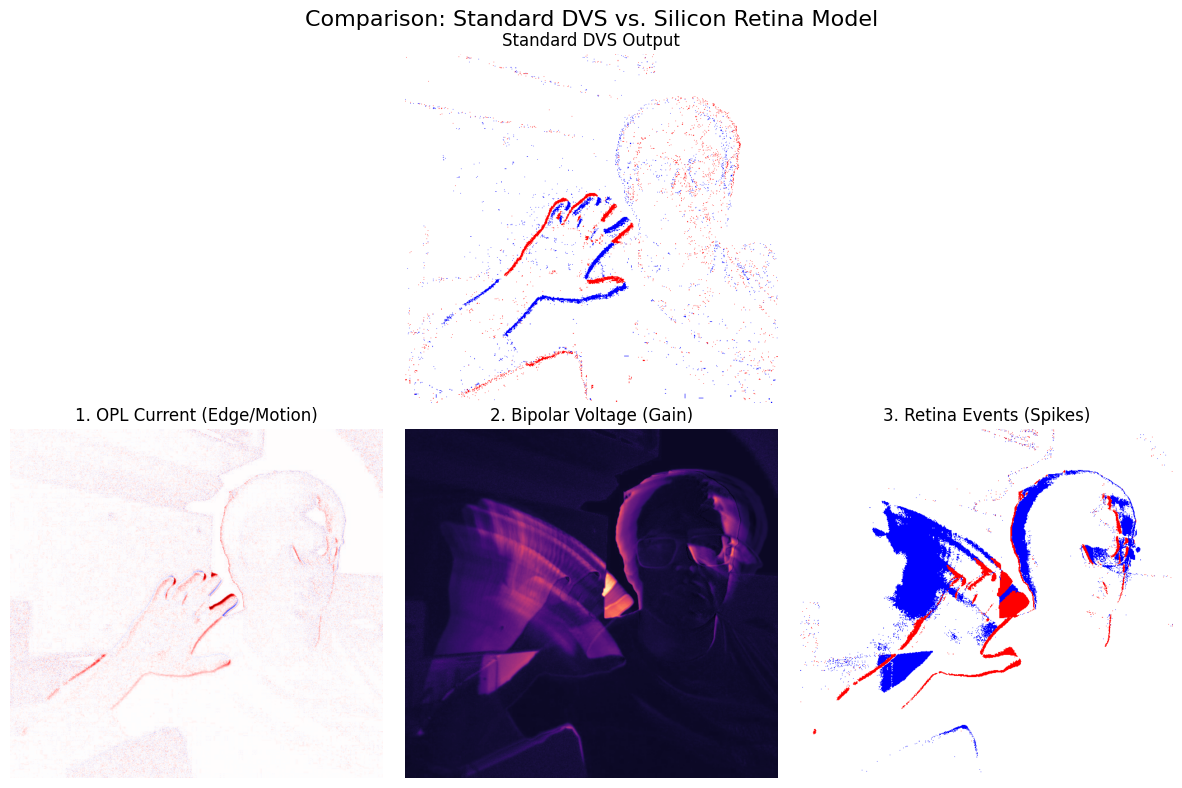

In [15]:
# --- 1. Prepare Data ---
# DVS Image (Top Row)
dvs_img_bgr = visualize_events(events, width=W, height=H,
                               t_start=int(start_frame / FPS * 1e9),
                               t_end=int(end_frame / FPS * 1e9))
dvs_img_rgb = cv2.cvtColor(dvs_img_bgr, cv2.COLOR_BGR2RGB)

# Retina Event Image (Bottom Row - Output)
retina_evt_bgr = visualize_retina_frames(positive, negative, start_frame, end_frame, H, W)
retina_evt_rgb = cv2.cvtColor(retina_evt_bgr, cv2.COLOR_BGR2RGB)

# Intermediate: OPL (Center-Surround)
# Use the middle frame of the window for the snapshot
mid_idx = (end_frame - start_frame) // 2
opl_img_rgb = visualize_heatmap(opl_stack, mid_idx, cmap_name='seismic', normalize_sym=True)

# Intermediate: Bipolar Voltage (Contrast Control)
bip_img_rgb = visualize_heatmap(bip_stack, mid_idx, cmap_name='magma', normalize_sym=False)


# --- 2. Plotting ---
fig = plt.figure(figsize=(12, 8))
plt.suptitle("Comparison: Standard DVS vs. Silicon Retina Model", fontsize=16)

# == ROW 1: Standard DVS ==
ax1 = plt.subplot(2, 3, 2) # Center it on the top row
ax1.imshow(dvs_img_rgb)
ax1.set_title("Standard DVS Output")
ax1.axis('off')

# == ROW 2: Silicon Retina Pipeline ==
# 2.1 OPL (Analog)
ax2 = plt.subplot(2, 3, 4)
ax2.imshow(opl_img_rgb)
ax2.set_title("1. OPL Current (Edge/Motion)")
ax2.axis('off')

# 2.2 Bipolar (Analog)
ax3 = plt.subplot(2, 3, 5)
ax3.imshow(bip_img_rgb)
ax3.set_title("2. Bipolar Voltage (Gain)")
ax3.axis('off')

# 2.3 Retina Output (Events)
ax4 = plt.subplot(2, 3, 6)
ax4.imshow(retina_evt_rgb)
ax4.set_title("3. Retina Events (Spikes)")
ax4.axis('off')

plt.tight_layout()
plt.savefig("visual_abstract.jpg", dpi=300)
plt.show()

In [16]:
import cv2
import os

# Create a directory for outputs to keep things organized
output_dir = "visual_abstract_assets"
os.makedirs(output_dir, exist_ok=True)

print(f"Saving raw images to {output_dir}...")

# --- 1. Save DVS Output ---
# We already have 'dvs_img_bgr' from the previous step, so we can save it directly.
cv2.imwrite(f"{output_dir}/1_standard_dvs.png", dvs_img_bgr)


# --- 2. Save OPL (Outer Plexiform Layer) ---
# 'opl_img_rgb' was created for matplotlib (RGB).
# We must convert it back to BGR for OpenCV saving.
opl_img_bgr = cv2.cvtColor(opl_img_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(f"{output_dir}/2_retina_stage1_opl.png", opl_img_bgr)


# --- 3. Save Bipolar/Gain Layer ---
# Same here: Convert RGB -> BGR
bip_img_bgr = cv2.cvtColor(bip_img_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(f"{output_dir}/3_retina_stage2_bipolar.png", bip_img_bgr)


# --- 4. Save Retina Events Output ---
# We already have 'retina_evt_bgr' from the previous step.
cv2.imwrite(f"{output_dir}/4_retina_stage3_events.png", retina_evt_bgr)

print("Done! Check the folder.")

Saving raw images to visual_abstract_assets...
Done! Check the folder.


In [17]:
# Select the middle frame of the captured window for the snapshot
mid_idx = (end_frame - start_frame) // 2

# --- Visualize LIF ON Membrane ---
# normalize_sym=False because voltage is usually 0 to Threshold (not negative)
lif_on_img_rgb = visualize_heatmap(v_lif_on_stack, mid_idx, cmap_name='inferno', normalize_sym=False)
lif_on_img_bgr = cv2.cvtColor(lif_on_img_rgb, cv2.COLOR_RGB2BGR)

# --- Visualize LIF OFF Membrane ---
lif_off_img_rgb = visualize_heatmap(v_lif_off_stack, mid_idx, cmap_name='inferno', normalize_sym=False)
lif_off_img_bgr = cv2.cvtColor(lif_off_img_rgb, cv2.COLOR_RGB2BGR)

# --- Save to Disk ---
output_dir = "visual_abstract_assets"
os.makedirs(output_dir, exist_ok=True)

cv2.imwrite(f"{output_dir}/5_retina_stage3_lif_on.png", lif_on_img_bgr)
cv2.imwrite(f"{output_dir}/6_retina_stage3_lif_off.png", lif_off_img_bgr)

print(f"Saved LIF membrane states to {output_dir}")

Saved LIF membrane states to visual_abstract_assets
